# Assignment 6: Data Preparation for Supervised Machine Learning

In this assignment, I will prepare the UCI Heart Disease dataset for machine learning. The goal is to predict whether a patient has heart disease based on medical measurements such as age, blood pressure, cholesterol, and maximum heart rate.

The dataset download contains many files, so I will first check all of them and choose the most suitable one, with reasons. Then I will follow a proper machine learning workflow:
- Choose and load the dataset
- Separate the features and the target, and split the data into 70% training and 30% testing
- Explore the training data
- Handle missing values, outliers, and categorical variables
- Scale the numerical features

I split the data before cleaning it, so that every value I use for cleaning (median, mode, 95th percentile, mean, and standard deviation) is learned only from the training data. This prevents data leakage, because the test set should act like new, unseen patients.

In [1]:
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
# Folder with all the downloaded files
data_folder = "heart_disease_data"

In [4]:
# List every file with its size
for f in sorted(os.listdir(data_folder)):
    path = os.path.join(data_folder, f)
    if os.path.isfile(path):
        print(f"{f:30s} {os.path.getsize(path):>8,} bytes")
    else:
        print(f"{f:30s} (folder)")
        

Index                               644 bytes
WARNING                             407 bytes
ask-detrano                         587 bytes
bak                               6,737 bytes
cleve.mod                        23,941 bytes
cleveland.data                   60,669 bytes
costs                          (folder)
heart-disease.names              10,060 bytes
hungarian.data                   62,192 bytes
long-beach-va.data               39,892 bytes
new.data                        389,771 bytes
processed.cleveland.data         18,461 bytes
processed.hungarian.data         10,263 bytes
processed.switzerland.data        4,109 bytes
processed.va.data                 6,737 bytes
reprocessed.hungarian.data       11,058 bytes
switzerland.data                 24,674 bytes


In [5]:
# Read the warning note left by the data creators
print("\n--- WARNING file ---")
print(open(os.path.join(data_folder, "WARNING")).read())


--- WARNING file ---
The file cleveland.data has been unfortunately messed up when we lost
node cip2 and loaded the file on node ics.  The file processed.cleveland.data
seems to be in good shape and is useable (for the 14 attributes situation).
I'll clean up cleveland.data as soon as possible.

Bad news: my original copy of the database appears to be corrupted.
I'll have to go back to the donor to get a new copy.

David Aha



## 1B: Comparing the Four Processed Datasets

In [6]:
# Column names from the heart-disease.names file (the processed files have no header row)
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

processed_files = {
    "Cleveland":   "processed.cleveland.data",
    "Hungary":     "processed.hungarian.data",
    "Switzerland": "processed.switzerland.data",
    "VA Long Beach": "processed.va.data"
}

summary = []
datasets = {}

for name, file in processed_files.items():
    data = pd.read_csv(os.path.join(data_folder, file), header=None,
                       names=cols, na_values="?")
    datasets[name] = data
    summary.append({
        "Dataset": name,
        "Rows": len(data),
        "Total missing values": int(data.isnull().sum().sum()),
        "Rows with any missing": int(data.isnull().any(axis=1).sum()),
        "Cholesterol = 0": int((data["chol"] == 0).sum()),
        "% with disease (num > 0)": round((data["num"] > 0).mean() * 100, 1)
    })

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

# Missing values (%) per column for each dataset
print("\nMissing values (%) per column:")
missing_pct = pd.DataFrame({name: (d.isnull().mean() * 100).round(1)
                            for name, d in datasets.items()})
print(missing_pct)

      Dataset  Rows  Total missing values  Rows with any missing  Cholesterol = 0  % with disease (num > 0)
    Cleveland   303                     6                      6                0                      45.9
      Hungary   294                   782                    293                0                      36.1
  Switzerland   123                   273                    123              123                      93.5
VA Long Beach   200                   698                    199               49                      74.5

Missing values (%) per column:
          Cleveland  Hungary  Switzerland  VA Long Beach
age             0.0      0.0          0.0            0.0
sex             0.0      0.0          0.0            0.0
cp              0.0      0.0          0.0            0.0
trestbps        0.0      0.3          1.6           28.0
chol            0.0      7.8          0.0            3.5
fbs             0.0      2.7         61.0            3.5
restecg         0.0      0.3 

### Interpretation

The Heart Disease download contains many files, so I listed all of them first to understand what each one is.

- The raw files (cleveland.data, hungarian.data, switzerland.data, long-beach-va.data, and new.data) contain all 76 original attributes, split across several lines per patient. They are hard to read and not in a simple table format.
- The processed files (processed.cleveland.data, processed.hungarian.data, processed.switzerland.data, and processed.va.data) contain only the 14 attributes most commonly used for research, with one patient per line and values separated by commas. Even though they end in .data instead of .csv, they are comma-separated, so pandas can read them with read_csv.
- heart-disease.names is the documentation file. It explains what each column means, and I used it to get the column names.
- The other files (Index, WARNING, ask-detrano, cleve.mod, bak, reprocessed.hungarian.data, and the costs folder) are notes and older or alternative versions of the data.

The WARNING file, written by the data creators, says that the raw cleveland.data file was corrupted, but processed.cleveland.data is in good shape and usable for the 14-attribute version. Because of this, I will only consider the processed files. Next, I will compare the four processed files to decide which one to use.

### Interpretation

I loaded all four processed files using the 14 column names from heart-disease.names, and treated "?" as a missing value. Then I compared them.

Comparison:
- Cleveland has 303 patients and only 6 missing values (in ca and thal), affecting just 6 rows. No cholesterol values are 0, and 45.9% of patients have heart disease.
- Hungary has 294 patients but 782 missing values, and 293 of its rows have at least one missing value. ca is 99% missing, thal is 90.5% missing, and slope is 64.6% missing. Only 36.1% of patients have heart disease.
- Switzerland has 123 patients, and every row has missing values. All 123 patients have a cholesterol value of 0. Since a living person cannot have zero cholesterol, these are hidden missing values. Also, 93.5% of patients have heart disease, so the classes are very unbalanced.
- VA Long Beach has 200 patients, and 199 rows have missing values. ca is 99% missing, thal is 83% missing, and about 27% to 28% of trestbps, thalach, exang, and oldpeak are missing. 49 patients have cholesterol = 0, and 74.5% have heart disease.

## Dataset choice: processed.cleveland.data

I chose processed.cleveland.data for these reasons:
- The data creators' WARNING file says the raw cleveland.data file is corrupted, but processed.cleveland.data is in good shape and usable.
- It is by far the most complete dataset, with only 6 missing values out of 303 rows.
- It has no impossible values like cholesterol = 0.
- The classes are fairly balanced (45.9% with disease and 54.1% without), which is good for training a classification model.
- It is the version used in most research and machine learning studies on this data, so results can be compared with others.

I decided not to combine all four files. The other three datasets have most of their ca and thal values missing, so combining them would force me to drop these two columns, even though they are important medical indicators. The datasets also come from patient groups with very different disease rates (from 36% to 93.5%), so mixing them could confuse the model.

# Part 2: Load the Chosen Dataset

In [7]:
# Use the Cleveland dataset loaded in 1B
heart_df = datasets["Cleveland"].copy()

In [8]:
print(heart_df.head())


    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0   3.0    0  
4    1.0  0.0   3.0    0  


In [9]:
# Convert the target to binary: 0 = no disease, 1 = disease (num 1 to 4)
print("Original target values (num):")
print(heart_df["num"].value_counts().sort_index())

heart_df["target"] = (heart_df["num"] > 0).astype(int)
heart_df = heart_df.drop("num", axis=1)

print("\nNew binary target:")
print(heart_df["target"].value_counts().sort_index())

Original target values (num):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

New binary target:
target
0    164
1    139
Name: count, dtype: int64


In [10]:
print("\nShape:", heart_df.shape)
heart_df.info()


Shape: (303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


### Interpretation

I used the Cleveland dataset and created a binary target column.

The original target, num, shows the level of heart disease from 0 to 4:
- 0 (no disease): 164 patients
- 1: 55 patients
- 2: 36 patients
- 3: 35 patients
- 4: 13 patients

I converted it into a new column called target, where 0 means no heart disease and 1 means heart disease (num 1 to 4). I did this for two reasons. First, the heart-disease.names file says most research focuses on whether heart disease is present or not. Second, levels 3 and 4 have very few patients (35 and 13), which is not enough for a model to learn from. After the change, there are 164 patients without disease (54.1%) and 139 with disease (45.9%), so the classes are fairly balanced. I then dropped the original num column, because keeping it would give the model the answer (data leakage).

From info():
- The dataset has 303 rows and 14 columns: 13 features and the target.
- ca has 299 non-null values (4 missing) and thal has 301 (2 missing). All other columns are complete.
- All features are stored as float64 (decimal numbers), even columns that are actually categories, such as sex, cp (chest pain type), and thal. Because pandas sees them as numbers, I will need to identify the categorical columns myself before encoding.

# Part 3: Separate the Target and Split the Data (70% Training, 30% Testing)

In [11]:
# Separate features (X) and target (y)
X = heart_df.drop("target", axis=1)
y = heart_df["target"]

# 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nTarget balance - train (%):")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("\nTarget balance - test (%):")
print((y_test.value_counts(normalize=True) * 100).round(1))

X_train: (212, 13)
X_test: (91, 13)

Target balance - train (%):
target
0    54.2
1    45.8
Name: proportion, dtype: float64

Target balance - test (%):
target
0    53.8
1    46.2
Name: proportion, dtype: float64


# Part 4: Exploratory Data Analysis (Training Data)

I explore only the training data, so that no decisions are based on the test set.

In [12]:
# First few rows
display(X_train.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
230,52.0,0.0,3.0,136.0,196.0,0.0,2.0,169.0,0.0,0.1,2.0,0.0,3.0
43,59.0,1.0,3.0,150.0,212.0,1.0,0.0,157.0,0.0,1.6,1.0,0.0,3.0
283,35.0,1.0,2.0,122.0,192.0,0.0,0.0,174.0,0.0,0.0,1.0,0.0,3.0
206,58.0,1.0,4.0,128.0,259.0,0.0,2.0,130.0,1.0,3.0,2.0,2.0,7.0
42,71.0,0.0,2.0,160.0,302.0,0.0,0.0,162.0,0.0,0.4,1.0,2.0,3.0


In [13]:
# Summary statistics
display(X_train.describe().round(2))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,212.00,212.00,212.00,212.00,212.00,212.00,212.00,212.00,212.00,212.00,212.00,212.00,211.00
mean,54.61,0.69,3.18,130.02,249.70,0.12,1.01,149.69,0.32,1.00,1.58,0.63,4.67
std,8.95,0.46,0.94,16.52,54.93,0.33,1.00,22.03,0.47,1.12,0.61,0.90,1.94
min,34.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.75,0.00,0.00,1.00,0.00,3.00
50%,55.00,1.00,3.00,130.00,245.00,0.00,2.00,153.00,0.00,0.80,2.00,0.00,3.00
75%,61.25,1.00,4.00,140.00,277.25,0.00,2.00,165.00,1.00,1.60,2.00,1.00,7.00
max,77.00,1.00,4.00,192.00,564.00,1.00,2.00,195.00,1.00,6.20,3.00,3.00,7.00


In [14]:
# Missing values in the training set
print("Missing values in X_train:")
print(X_train.isnull().sum())

Missing values in X_train:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        1
dtype: int64


In [15]:
# Number of unique values per column (helps spot categorical columns)
print("\nUnique values per column:")
print(X_train.nunique())



Unique values per column:
age          38
sex           2
cp            4
trestbps     41
chol        126
fbs           2
restecg       3
thalach      80
exang         2
oldpeak      36
slope         3
ca            4
thal          3
dtype: int64


### Interpretation

I explored only the training data (212 patients) to avoid using the test set for decisions.

- Missing values: only 1 in thal. The other 5 missing values (4 in ca, 1 in thal) are in the test set, so I will fill both sets using values learned from the training data.
- Outliers: chol (max 564 vs 75th percentile 277), trestbps (max 192 vs 140), and oldpeak (max 6.2 vs 1.6) have high outliers, and thalach has a low outlier (min 71).
- No impossible values like zero cholesterol or blood pressure.
- About 69% of patients are male, 12% have high fasting blood sugar, and 32% have exercise-induced chest pain.
- The features are on very different scales, so scaling will be needed.

Column types (from unique values):
- Binary (already 0/1): sex, fbs, exang
- Categorical (need one-hot encoding): cp, restecg, slope, thal. Their numbers are labels, not amounts.
- Numerical: age, trestbps, chol, thalach, oldpeak, and ca (a count of blood vessels, 0 to 3)

# Part 5: Handle Missing Data

In [16]:
# Identify columns with missing values (train and test)
missing_table = pd.DataFrame({
    "Train missing": X_train.isnull().sum(),
    "Test missing": X_test.isnull().sum(),
    "Train missing %": (X_train.isnull().mean() * 100).round(1)
})
print(missing_table[(missing_table["Train missing"] > 0) | (missing_table["Test missing"] > 0)])

      Train missing  Test missing  Train missing %
ca                0             4              0.0
thal              1             1              0.5


In [17]:
#Drop columns with too many missing values (more than 30% in training data)
threshold = 30
cols_to_drop = missing_table[missing_table["Train missing %"] > threshold].index.tolist()
print("\nColumns dropped (more than 30% missing):", cols_to_drop)
X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)


Columns dropped (more than 30% missing): []


In [19]:
# Numerical column -> median, learned from training data
ca_median = X_train["ca"].median()
print("\nMedian of ca (from train):", ca_median)


Median of ca (from train): 0.0


In [21]:
#Categorical column -> mode, learned from training data
thal_mode = X_train["thal"].mode()[0]
print("Mode of thal (from train):", thal_mode)


Mode of thal (from train): 3.0


In [24]:
# Apply the SAME values to both train and test
for data in (X_train, X_test):
    data["ca"] = data["ca"].fillna(ca_median)
    data["thal"] = data["thal"].fillna(thal_mode)

# Check
print("\nMissing values left - train:", X_train.isnull().sum().sum())
print("Missing values left - test:", X_test.isnull().sum().sum())



Missing values left - train: 0
Missing values left - test: 0


### Interpretation

- Missing values: ca has 4 missing values (all in the test set), and thal has 1 missing value in the training set and 1 in the test set.
- No column was dropped. I set a limit of 30% missing values, and the highest missing rate in the training data was only 0.5% (thal), so all columns were kept.
- For ca (a numerical column), I filled missing values with the median from the training data, which is 0. This means most patients have no major blood vessels coloured by fluoroscopy. I used the median because outliers do not affect it.
- For thal (a categorical column), I filled missing values with the mode from the training data, which is 3 (normal). I used the mode because an average does not make sense for categories.
- I applied the same values to both the training and test sets, so the test data is filled using only what was learned from the training data.
- After filling, there are no missing values left in either set.

# Part 6: Dealing with Outliers

## 6A: Identify Outliers with Boxplots

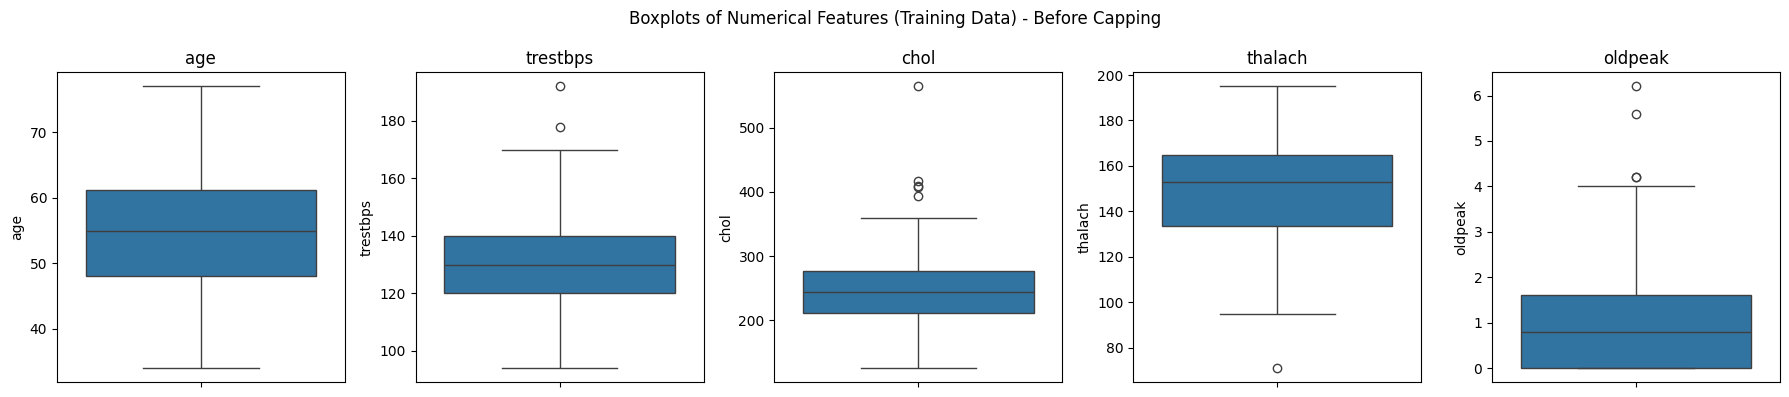

In [25]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots of Numerical Features (Training Data) - Before Capping")
plt.tight_layout()
plt.show()

## 6B: Cap Outliers at the 95th Percentile

In [26]:
cap_cols = ["trestbps", "chol", "oldpeak"]

for col in cap_cols:
    cap = X_train[col].quantile(0.95)                   # learned from training data only
    n_train = (X_train[col] > cap).sum()
    n_test = (X_test[col] > cap).sum()
    X_train[col] = X_train[col].clip(upper=cap)
    X_test[col] = X_test[col].clip(upper=cap)           # same cap applied to test
    print(f"{col:9s} 95th percentile cap = {cap:6.2f} | values capped: train {n_train}, test {n_test}")


trestbps  95th percentile cap = 160.00 | values capped: train 6, test 9
chol      95th percentile cap = 332.25 | values capped: train 11, test 2
oldpeak   95th percentile cap =   3.00 | values capped: train 10, test 10


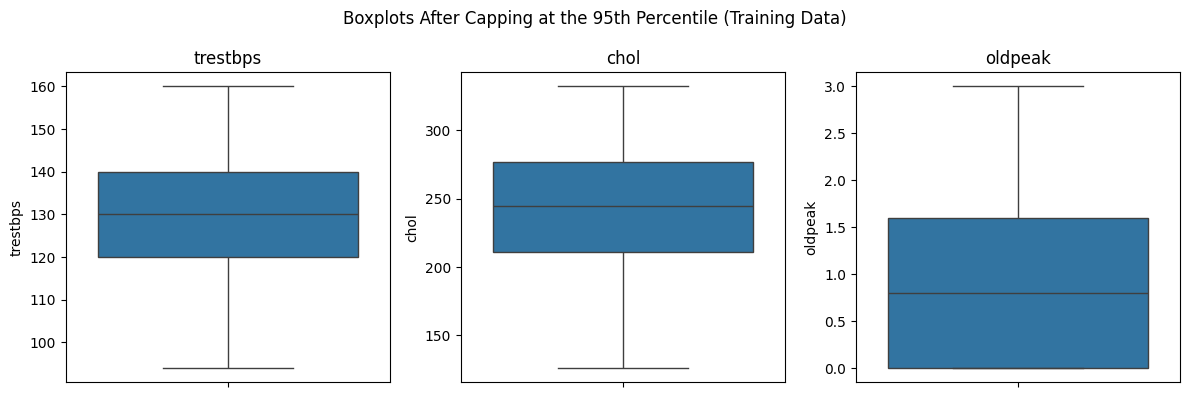

In [27]:
# Boxplots after capping
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, cap_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots After Capping at the 95th Percentile (Training Data)")
plt.tight_layout()
plt.show()

### Interpretation

Boxplots before capping (training data):
- age has no outliers.
- trestbps has 2 high outliers (about 178 and 192 mm Hg).
- chol has 5 high outliers, the largest being 564 mg/dl.
- oldpeak has 4 high outliers, up to 6.2.
- thalach has 1 low outlier (71).

Capping:
I capped trestbps, chol, and oldpeak at their 95th percentile, calculated from the training data only, and applied the same caps to the test set. Any value above the cap was replaced by the cap, so no patients were removed. This is better than deleting rows, because the dataset is small.
- trestbps cap: [160.00] ([x] values capped in train, [x] in test)
- chol cap: [332.xx] ([x] in train, [x] in test)
- oldpeak cap: [3.00] ([x] in train, [x] in test)

After capping, the boxplots show no more outliers for these three columns.

I did not cap thalach, because its outlier is a low value, and a 95th percentile cap only limits high values.

# Part 7: Handling Categorical Variables

In [30]:
# Identify categorical columns (from the unique values in Part 4)
cat_cols = ["cp", "restecg", "slope", "thal"]
binary_cols = ["sex", "fbs", "exang"]
print("Categorical columns to encode:", cat_cols)
print("Binary columns (already 0/1, no encoding needed):", binary_cols)

Categorical columns to encode: ['cp', 'restecg', 'slope', 'thal']
Binary columns (already 0/1, no encoding needed): ['sex', 'fbs', 'exang']


In [29]:
# Change category codes from decimals (3.0) to whole numbers (3) for cleaner column names
for col in cat_cols:
    X_train[col] = X_train[col].astype(int)
    X_test[col] = X_test[col].astype(int)
    

In [31]:
# One-Hot Encoding
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

In [32]:
# Make sure the test set has exactly the same columns as the training set
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)


In [33]:
print("\nShape before encoding - train:", X_train.shape, "| test:", X_test.shape)
print("Shape after encoding  - train:", X_train_enc.shape, "| test:", X_test_enc.shape)
print("\nNew columns:")
print([c for c in X_train_enc.columns if c.startswith(tuple(cat_cols))])


Shape before encoding - train: (212, 13) | test: (91, 13)
Shape after encoding  - train: (212, 18) | test: (91, 18)

New columns:
['thalach', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2', 'slope_2', 'slope_3', 'thal_6', 'thal_7']


In [34]:
print([c for c in X_train_enc.columns if c not in X_train.columns])


['cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2', 'slope_2', 'slope_3', 'thal_6', 'thal_7']


### Interpretation

I identified 4 categorical columns: cp (chest pain type), restecg (resting ECG result), slope, and thal. Their numbers are labels, not amounts, so the model should not treat them as larger or smaller values. sex, fbs, and exang are already 0/1, so they did not need encoding.

I used one-hot encoding with drop_first=True, which turned each categorical column into 0/1 columns and dropped the first category to avoid repeating information:
- cp (4 types) became cp_2, cp_3, cp_4 (type 1 is when all three are 0)
- restecg (3 values) became restecg_1, restecg_2
- slope (3 values) became slope_2, slope_3
- thal (3, 6, 7) became thal_6, thal_7 (thal = 3, normal, is when both are 0)

The data went from 13 to 18 columns in both the training and test sets. I used reindex to make sure the test set has exactly the same columns, in the same order, as the training set.

# Part 8: Feature Scaling

In [35]:
# Numerical columns to scale (0/1 columns are left as they are)
scale_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

In [36]:
X_train_scaled = X_train_enc.copy()
X_test_scaled = X_test_enc.copy()

In [37]:
scaler = StandardScaler()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train_enc[scale_cols])   # learn + scale train
X_test_scaled[scale_cols] = scaler.transform(X_test_enc[scale_cols])         # scale test with train's mean/std

In [38]:
# Check: before vs after (training data)
print("Before scaling (train):")
print(X_train_enc[scale_cols].describe().loc[["mean", "std"]].round(2))
print("\nAfter scaling (train):")
print(X_train_scaled[scale_cols].describe().loc[["mean", "std"]].round(2))
print("\nAfter scaling (test):")
print(X_test_scaled[scale_cols].describe().loc[["mean", "std"]].round(2))

Before scaling (train):
        age  trestbps    chol  thalach  oldpeak    ca
mean  54.61    129.62  246.81   149.69     0.94  0.63
std    8.95     15.51   46.47    22.03     0.96  0.90

After scaling (train):
      age  trestbps  chol  thalach  oldpeak   ca
mean -0.0      -0.0  -0.0     -0.0      0.0  0.0
std   1.0       1.0   1.0      1.0      1.0  1.0

After scaling (test):
       age  trestbps  chol  thalach  oldpeak    ca
mean -0.07      0.27 -0.16    -0.01     0.13  0.12
std   1.04      1.02  0.92     1.13     1.17  1.12


### Interpretation

I scaled the 6 numerical columns (age, trestbps, chol, thalach, oldpeak, and ca) with StandardScaler, so each has a mean of 0 and a standard deviation of 1. I did not scale the 0/1 columns, because they are already on a small, meaningful scale.

- Before scaling, the columns were on very different scales. For example, chol had a mean of 246.81 while oldpeak had a mean of 0.94. These means are slightly lower than in Part 4 because of the outlier capping in Part 6.
- After scaling, every column in the training set has a mean of 0 and a standard deviation of 1. (-0.0 is just a very small number rounded to zero.)
- The test set is close to 0 and 1 but not exact (for example, trestbps has a mean of 0.27). This is expected, because I scaled it using the training set's mean and standard deviation, not its own. This shows there is no data leakage.

Scaling makes sure no feature dominates just because it has bigger numbers, which matters for models that use distances, like KNN and SVM.

# Part 9: Final Data Ready for Modelling

In [39]:
# Final check: shapes, missing values, matching columns, target separated
print("X_train:", X_train_scaled.shape, "| y_train:", y_train.shape)
print("X_test:", X_test_scaled.shape, "| y_test:", y_test.shape)
print("\nMissing values - train:", X_train_scaled.isnull().sum().sum(),
      "| test:", X_test_scaled.isnull().sum().sum())
print("Same columns in train and test:", list(X_train_scaled.columns) == list(X_test_scaled.columns))
print("Target in features:", "target" in X_train_scaled.columns)

display(X_train_scaled.head())

X_train: (212, 18) | y_train: (212,)
X_test: (91, 18) | y_test: (91,)

Missing values - train: 0 | test: 0
Same columns in train and test: True
Target in features: False


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6,thal_7
230,-0.292768,0.0,0.412022,-1.095954,0.0,0.878399,0.0,-0.879504,-0.703163,0,1,0,0,1,1,0,0,0
43,0.491469,1.0,1.316520,-0.750841,1.0,0.332431,0.0,0.687344,-0.703163,0,1,0,0,0,0,0,0,0
283,-2.197344,1.0,-0.492476,-1.182233,0.0,1.105886,0.0,-0.983961,-0.703163,1,0,0,0,0,0,0,0,0
206,0.379436,1.0,-0.104834,0.262930,0.0,-0.895997,1.0,2.149735,1.521770,0,0,1,0,1,1,0,0,1
42,1.835876,0.0,1.962590,1.190423,0.0,0.559918,0.0,-0.566135,1.521770,1,0,0,0,0,0,0,0,0


### Interpretation

The data is now ready for modelling:
- The training set has 212 patients and the test set has 91 patients, each with 18 features. The targets (y_train and y_test) match these row counts.
- There are no missing values in either set.
- The training and test sets have exactly the same columns in the same order.
- The target column is not in the feature matrix, so the model cannot see the answer.
- The numerical features are scaled, the categorical features are one-hot encoded, and the binary features are kept as 0/1.